# Chicago Traffic Crash Analysis (2016–2025)
**Daniel Alejandro Berrio Restrepo**

A revised, executable analysis derived from the supplied portfolio notebook. Which crash circumstances form distinct profiles, how do injury proportions differ, and how sensitive are the profiles to K, gamma, scaling and initialization?

Source: [City of Chicago: Traffic Crashes – Crashes](https://data.cityofchicago.org/Transportation/Traffic-Crashes-Crashes/85ca-t3if/about_data). Download the CSV from the official portal; the exact supplied snapshot is identified by SHA-256 below. The live dataset changes. Results describe reported crashes, not exposure-adjusted risk.

The earlier notebook scaled the full population before sampling. This revision splits records first, fits scaling only on training data and keeps crash IDs throughout. Saved outputs are replaced by this execution. No injury variable enters clustering.

In [1]:
import os, sys, csv, hashlib, json, time, platform
from pathlib import Path
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display
from kmodes.kprototypes import KPrototypes
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.spatial.distance import cdist

# Colab: install requirements.txt in a preceding cell, upload the CSV to /content/data,
# or mount your own Drive and set CHICAGO_CSV. Never commit a personal Drive path.
CSV_PATH = Path(os.environ.get('CHICAGO_CSV', '/content/data/Traffic_Crashes_-_Crashes_20261001.csv'))
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
ASSETS = ROOT / 'assets'; REPORTS = ROOT / 'reports'
ASSETS.mkdir(exist_ok=True); REPORTS.mkdir(exist_ok=True)
SEED = 42
N_TRAIN, N_EVAL = 30_000, 5_000
NUM = ['POSTED_SPEED_LIMIT', 'NUM_UNITS']
CAT = ['PERIODO_DIA', 'WEATHER_CONDITION', 'LIGHTING_CONDITION',
       'ROADWAY_SURFACE_COND', 'TRAFFIC_CONTROL_DEVICE', 'TRAFFICWAY_TYPE',
       'FIRST_CRASH_TYPE', 'ALIGNMENT']
FEATURES = NUM + CAT
CAT_IDX = list(range(len(NUM), len(FEATURES)))
versions = {p: metadata.version(p) for p in ['numpy','pandas','polars','matplotlib','kmodes','scikit-learn','scipy','nbformat','nbclient','ipykernel']}
print('Python:', platform.python_version()); display(pd.Series(versions, name='installed version'))

Python: 3.12.14


numpy            2.5.4
pandas           3.1.0
polars           2.1.0
matplotlib      3.11.2
kmodes          0.12.2
scikit-learn     1.9.1
scipy           1.18.1
nbformat        5.11.1
nbclient        0.11.0
ipykernel        7.4.0
Name: installed version, dtype: str

## Strict integrity audit
Read every CSV record with strict quoting and verify its width before loading with Polars. Fail explicitly on malformed records, invalid required numeric values or unparseable dates. No silent row skipping or field imputation. The original file is read only. Semantic checks are distinct from CSV syntax checks.

In [2]:
digest = hashlib.sha256()
with CSV_PATH.open('rb') as f:
    for block in iter(lambda: f.read(1024 * 1024), b''): digest.update(block)
width_errors = []
with CSV_PATH.open(encoding='utf-8-sig', newline='') as f:
    reader = csv.reader(f, strict=True)
    header = next(reader); records = 0
    for row in reader:
        records += 1
        if len(row) != len(header):
            width_errors.append({'record': records, 'physical_line': reader.line_num, 'fields': len(row)})
audit = {'bytes': CSV_PATH.stat().st_size, 'sha256': digest.hexdigest(),
         'records': records, 'columns': len(header), 'width_errors': width_errors}
print(json.dumps(audit, indent=2))
assert not width_errors, 'Malformed CSV records; stop and investigate without modifying the original.'
raw = pl.read_csv(CSV_PATH, infer_schema_length=None, ignore_errors=False)
assert raw.height == records
assert raw['CRASH_RECORD_ID'].null_count() == 0
assert raw['CRASH_RECORD_ID'].n_unique() == records, 'Duplicate crash identifiers require investigation.'
raw = raw.with_row_index('SOURCE_ROW').with_columns(
    pl.col('CRASH_DATE').str.to_datetime(format='%m/%d/%Y %I:%M:%S %p', strict=True))
assert raw['CRASH_DATE'].null_count() == 0
for c in NUM + ['INJURIES_TOTAL']:
    raw = raw.with_columns(pl.col(c).cast(pl.Float64, strict=True))
audit['duplicate_crash_ids'] = records - raw['CRASH_RECORD_ID'].n_unique()
audit['negative_speed_limits'] = raw.filter(pl.col('POSTED_SPEED_LIMIT') < 0).height
audit['nonpositive_units'] = raw.filter(pl.col('NUM_UNITS') <= 0).height
audit['negative_injuries'] = raw.filter(pl.col('INJURIES_TOTAL') < 0).height
assert audit['negative_injuries'] == 0
print('Semantic checks:', {k:v for k,v in audit.items() if k not in ['width_errors','sha256']})
display(raw.select(pl.all().null_count()).transpose(include_header=True, header_name='column', column_names=['missing']).filter(pl.col('missing') > 0))

{
  "bytes": 691590077,
  "sha256": "45d49be74689f4fc912e89b0494fb1eeb3adb5c876b99f5a41ae645217f75653",
  "records": 1099438,
  "columns": 49,
  "width_errors": []
}


Semantic checks: {'bytes': 691590077, 'records': 1099438, 'columns': 49, 'duplicate_crash_ids': 0, 'negative_speed_limits': 0, 'nonpositive_units': 0, 'negative_injuries': 0}


column,missing
str,u32
"""CRASH_DATE_EST_I""",1020049
"""LANE_CNT""",900391
"""REPORT_TYPE""",37634
"""INTERSECTION_RELATED_I""",847401
"""NOT_RIGHT_OF_WAY_I""",1050565
…,…
"""INJURIES_UNKNOWN""",2375
"""IDOT_CONTROL_NO""",2811
"""LATITUDE""",8570


## Cohort and preparation
Use 2016–2025 inclusive. Preserve unknown/not applicable categories as reported. Normalize category whitespace and case. Missing model features, if present, are explicitly excluded and counted; injury missingness is retained and reported separately. There is no imputation. Posted speed limit is the legal road limit, not observed vehicle speed. Time of day follows the original four six-hour periods. Geographic availability is audited; clustering does not use coordinates.

{
  "bytes": 691590077,
  "sha256": "45d49be74689f4fc912e89b0494fb1eeb3adb5c876b99f5a41ae645217f75653",
  "records": 1099438,
  "columns": 49,
  "width_errors": [],
  "duplicate_crash_ids": 0,
  "negative_speed_limits": 0,
  "nonpositive_units": 0,
  "negative_injuries": 0,
  "period_records": 1006003,
  "outside_period": 93435,
  "missing_or_nonfinite_model_features_excluded": 0,
  "modeled_records": 1006003,
  "missing_injury_outcomes": 2189,
  "zero_coordinates": 74
}


,year,len
0,2016,44297
1,2017,83786
2,2018,118952
3,2019,117764
4,2020,92096
5,2021,108767
6,2022,108413
7,2023,110754
8,2024,112057
9,2025,109117


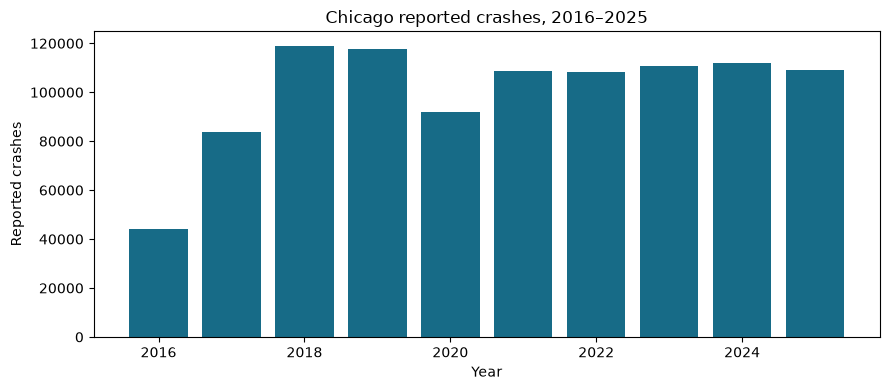

475

In [3]:
period = raw.filter(pl.col('CRASH_DATE').dt.year().is_between(2016, 2025))
period = period.with_columns(
    pl.when(pl.col('CRASH_DATE').dt.hour() < 6).then(pl.lit('OVERNIGHT'))
    .when(pl.col('CRASH_DATE').dt.hour() < 12).then(pl.lit('MORNING'))
    .when(pl.col('CRASH_DATE').dt.hour() < 18).then(pl.lit('AFTERNOON'))
    .otherwise(pl.lit('EVENING')).alias('PERIODO_DIA'))
period = period.with_columns([pl.col(c).str.strip_chars().str.to_uppercase() for c in CAT])
valid = pl.all_horizontal([pl.col(c).is_not_null() for c in FEATURES]) & pl.all_horizontal([pl.col(c).is_finite() for c in NUM])
cohort = period.filter(valid)
audit.update({'period_records': period.height, 'outside_period': raw.height-period.height,
              'missing_or_nonfinite_model_features_excluded': period.height-cohort.height,
              'modeled_records': cohort.height,
              'missing_injury_outcomes': cohort['INJURIES_TOTAL'].null_count(),
              'zero_coordinates': raw.filter((pl.col('LATITUDE') == 0) & (pl.col('LONGITUDE') == 0)).height})
print(json.dumps(audit, indent=2))
annual = period.group_by(pl.col('CRASH_DATE').dt.year().alias('year')).len().sort('year').to_pandas()
display(annual)
fig, ax = plt.subplots(figsize=(9,4)); ax.bar(annual['year'],annual['len'],color='#176b87')
ax.set(xlabel='Year',ylabel='Reported crashes',title='Chicago reported crashes, 2016–2025')
fig.tight_layout(); fig.savefig(ASSETS/'annual_crashes.png',dpi=160); plt.show()
(REPORTS/'integrity.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')

## Split before fitting transformations
Sample 30,000 training and 5,000 evaluation records without replacement. All remaining eligible records receive labels only after model selection. Fit median/IQR scaling on training only; when IQR is zero use training standard deviation (ddof=1), then 1 if constant. The primary configuration clips scaled numerical features to [-4,4], as in the supplied notebook's final configuration. This limits outlier influence. Hold evaluation data out of selection and stability experiments.

In [4]:
sample = cohort.sample(n=N_TRAIN+N_EVAL,with_replacement=False,shuffle=True,seed=SEED)
train = sample.head(N_TRAIN); evaluation = sample.tail(N_EVAL)
assert set(train['CRASH_RECORD_ID']).isdisjoint(set(evaluation['CRASH_RECORD_ID']))
scale = {}
for c in NUM:
    median = float(train[c].median()); iqr = float(train[c].quantile(.75)-train[c].quantile(.25))
    denominator = iqr if iqr > 0 else float(train[c].std())
    scale[c] = {'median':median,'scale':denominator if denominator > 0 else 1.0}
display(pd.DataFrame(scale).T)
def matrix(frame, clip=True):
    nums = frame.select(NUM).to_numpy().astype(float)
    for j,c in enumerate(NUM): nums[:,j] = (nums[:,j]-scale[c]['median'])/scale[c]['scale']
    if clip: nums = np.clip(nums,-4,4)
    x = np.empty((frame.height,len(FEATURES)),dtype=object)
    x[:,:len(NUM)] = nums; x[:,len(NUM):] = frame.select(CAT).to_numpy()
    return x
X_train = matrix(train); X_eval = matrix(evaluation)
probe_idx = np.random.default_rng(SEED).choice(N_TRAIN,1000,replace=False)
probe = X_train[probe_idx]
def mixed_distance(x,gamma):
    d = cdist(x[:,:2].astype(float),x[:,:2].astype(float),metric='sqeuclidean')
    for j in CAT_IDX: d += gamma*(x[:,j,None] != x[None,:,j])
    np.fill_diagonal(d,0)
    return d
D = mixed_distance(probe,2.0)
def fit_model(x,k,gamma,seed=SEED,n_init=10):
    started=time.time()
    m=KPrototypes(n_clusters=k,gamma=gamma,init='Huang',n_init=n_init,
                  max_iter=100,random_state=seed,n_jobs=1,verbose=0)
    m.fit(x,categorical=CAT_IDX)
    print(f'Fit K={k}, gamma={gamma}, seed={seed}: {time.time()-started:.1f}s',flush=True)
    return m

,median,scale
POSTED_SPEED_LIMIT,30.0,6.078525
NUM_UNITS,2.0,0.463218


## K selection using training only
At fixed gamma=2, compare K=2,3,4,5 using the silhouette of the same 1,000 training records under squared numerical distance plus gamma-weighted categorical mismatches. This is the K-Prototypes dissimilarity, not a Euclidean silhouette. Require at least 1% of training records in every group; select the largest silhouette among eligible K values (smaller K breaks exact ties). Silhouette is an exploratory heuristic. Costs are comparable within the same feature treatment and gamma; falling cost alone cannot select K.

Gamma=2 is a prespecified reference retained from the original final configuration, not claimed optimal. Later experiments vary it; injury outcomes never drive selection.

Every fit uses 10 Huang initializations and up to 100 iterations, retaining the lowest-cost solution. An initial exploratory run with two initializations showed poor seed stability; the complete workflow was rerun with this stronger optimization budget. Remaining instability is reported rather than hidden.

In [5]:
models = {}; comparisons=[]
for k in [2,3,4,5]:
    m=fit_model(X_train,k,2.0); models[k]=m
    labels=m.predict(probe,categorical=CAT_IDX)
    minimum=np.bincount(m.labels_,minlength=k).min()/N_TRAIN
    comparisons.append({'K':k,'gamma':2.0,'cost_per_training_record':m.cost_/N_TRAIN,
                        'silhouette':silhouette_score(D,labels,metric='precomputed'),
                        'minimum_training_share':minimum,'iterations':m.n_iter_})
comparison=pd.DataFrame(comparisons)
display(comparison)
eligible=comparison[comparison.minimum_training_share >= .01]
assert len(eligible)>0
K=int(eligible.sort_values(['silhouette','K'],ascending=[False,True]).iloc[0]['K'])
model=models[K]; baseline_probe=model.predict(probe,categorical=CAT_IDX)
print('Selected K:',K,'; fixed gamma: 2.0')
comparison.to_csv(REPORTS/'configurations.csv',index=False)

Fit K=2, gamma=2.0, seed=42: 77.5s


Fit K=3, gamma=2.0, seed=42: 106.1s


Fit K=4, gamma=2.0, seed=42: 102.4s


Fit K=5, gamma=2.0, seed=42: 96.2s


,K,gamma,cost_per_training_record,silhouette,minimum_training_share,iterations
0,2,2.0,7.258235,0.216343,0.329467,5
1,3,2.0,6.582967,0.195514,0.118133,7
2,4,2.0,6.117021,0.124030,0.095300,5
3,5,2.0,5.852925,0.151662,0.065867,4


Selected K: 2 ; fixed gamma: 2.0


## Sensitivity and stability
Compare gamma=0.5,1,2,4 and removing clipping at the selected K. ARI measures agreement on the same training probe and is invariant to label permutation. Cross-gamma costs are not ranked. Repeat the final configuration with five additional initialization seeds, then three 80% training subsamples using the already training-fitted scaler. These checks measure sensitivity, not external predictive validation; evaluation remains untouched.

Fit K=2, gamma=0.5, seed=42: 59.5s


Fit K=2, gamma=1.0, seed=42: 78.3s


Fit K=2, gamma=4.0, seed=42: 75.5s


Fit K=2, gamma=2.0, seed=42: 79.7s


,gamma,clipping,ARI_to_reference,silhouette_own_distance
0,0.5,True,0.147902,0.622892
1,1.0,True,0.145356,0.515433
2,2.0,True,1.000000,0.216343
3,4.0,True,0.116820,0.132549
4,2.0,False,0.915818,0.215399


...

Fit K=2, gamma=2.0, seed=2026: 68.7s


Fit K=2, gamma=2.0, seed=7: 55.0s


Fit K=2, gamma=2.0, seed=19: 43.7s


Fit K=2, gamma=2.0, seed=73: 59.2s


,experiment,seed,ARI
0,initialization,7,0.020139
1,initialization,19,0.031830
2,initialization,73,0.995899
3,initialization,101,0.030997
4,initialization,2026,0.030997
5,80% training subset,7,0.030997
6,80% training subset,19,0.030997
7,80% training subset,73,0.030997


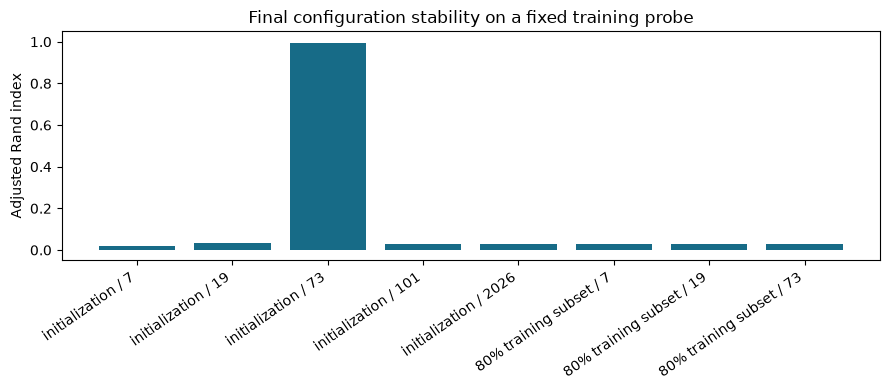

In [6]:
sensitivity=[]
for gamma,clip in [(.5,True),(1.,True),(2.,True),(4.,True),(2.,False)]:
    x=X_train if clip else matrix(train,clip=False)
    m=model if gamma==2 and clip else fit_model(x,K,gamma)
    p=m.predict(x[probe_idx],categorical=CAT_IDX)
    sensitivity.append({'gamma':gamma,'clipping':clip,'ARI_to_reference':adjusted_rand_score(baseline_probe,p),
                        'silhouette_own_distance':silhouette_score(mixed_distance(x[probe_idx],gamma),p,metric='precomputed')})
sensitivity=pd.DataFrame(sensitivity); display(sensitivity)
stability=[]
for seed in [7,19,73,101,2026]:
    m=fit_model(X_train,K,2.0,seed=seed)
    stability.append({'experiment':'initialization','seed':seed,'ARI':adjusted_rand_score(baseline_probe,m.predict(probe,categorical=CAT_IDX))})
for seed in [7,19,73]:
    idx=np.random.default_rng(seed).choice(N_TRAIN,int(.8*N_TRAIN),replace=False)
    m=fit_model(X_train[idx],K,2.0,seed=seed)
    stability.append({'experiment':'80% training subset','seed':seed,'ARI':adjusted_rand_score(baseline_probe,m.predict(probe,categorical=CAT_IDX))})
stability=pd.DataFrame(stability); display(stability)
sensitivity.to_csv(REPORTS/'sensitivity.csv',index=False); stability.to_csv(REPORTS/'stability.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4)); ax.bar(range(len(stability)),stability.ARI,color='#176b87')
ax.set_xticks(range(len(stability)),[f'{r.experiment} / {r.seed}' for r in stability.itertuples()],rotation=35,ha='right')
ax.set(ylabel='Adjusted Rand index',ylim=(-.05,1.05),title='Final configuration stability on a fixed training probe')
fig.tight_layout();fig.savefig(ASSETS/'stability.png',dpi=160);plt.show()

## Training versus held-out evaluation
Apply the frozen model and training-fitted transformation. Report group shares, within-group injury proportions and mean assigned dissimilarity. No evaluation-driven tuning or refitting follows. This random split tests within-snapshot consistency, not future generalization. Population summaries below include training/evaluation records and are descriptive.

In [7]:
def assigned_distance(x,labels,m):
    cent=m.cluster_centroids_
    a=cent[labels,:2].astype(float)
    d=((x[:,:2].astype(float)-a)**2).sum(axis=1)
    for j in CAT_IDX: d += m.gamma*(x[:,j] != cent[labels,j])
    return d
def profile(frame,labels,name):
    assert len(labels)==frame.height
    z=frame.select(['CRASH_RECORD_ID','INJURIES_TOTAL']+FEATURES).with_columns(pl.Series('cluster',labels))
    assert z['CRASH_RECORD_ID'].n_unique()==frame.height
    return z.group_by('cluster').agg(pl.len().alias('crashes'),
        pl.col('INJURIES_TOTAL').is_not_null().sum().alias('known_injury_outcomes'),
        (pl.col('INJURIES_TOTAL')>0).sum().alias('injury_crashes'),
        *[pl.col(c).mean().alias(c+'_mean') for c in NUM]).with_columns(
        (pl.col('crashes')/frame.height*100).alias('share_percent'),
        (pl.col('injury_crashes')/pl.col('known_injury_outcomes')*100).alias('injury_percent'),
        pl.lit(name).alias('sample')).sort('cluster').to_pandas()
train_labels=model.predict(X_train,categorical=CAT_IDX); eval_labels=model.predict(X_eval,categorical=CAT_IDX)
assert np.array_equal(train_labels,model.labels_)
comparison_samples=pd.concat([profile(train,train_labels,'training'),profile(evaluation,eval_labels,'evaluation')],ignore_index=True)
display(comparison_samples)
distance_summary={name:float(assigned_distance(x,y,model).mean()) for name,x,y in [('training',X_train,train_labels),('evaluation',X_eval,eval_labels)]}
print('Mean assigned dissimilarity:',distance_summary)
comparison_samples.to_csv(REPORTS/'train_evaluation.csv',index=False)

,cluster,crashes,known_injury_outcomes,injury_crashes,POSTED_SPEED_LIMIT_mean,NUM_UNITS_mean,share_percent,injury_percent,sample
0,0,9884,9847,1411,25.421388,2.043403,32.946667,14.329237,training
1,1,20116,20095,2921,29.851859,2.038377,67.053333,14.535954,training
2,0,1636,1628,233,25.801956,2.038509,32.720000,14.312039,evaluation
3,1,3364,3356,506,29.889715,2.037158,67.280000,15.077473,evaluation


Mean assigned dissimilarity: {'training': 7.258234577969468, 'evaluation': 7.213184576185822}


## Population labeling with explicit identity checks
Predict in batches, attach the original crash ID and source row at prediction time, and join by unique ID with one-to-one validation. Never reconstruct a random sample to recover label alignment. An independent prediction spot check verifies the joined labels.

,cluster,crashes,known_injury_outcomes,injury_crashes,POSTED_SPEED_LIMIT_mean,NUM_UNITS_mean,share_percent,injury_percent,sample
0,0,329743,328337,45257,25.515138,2.037587,32.777536,13.783704,population
1,1,676260,675477,99598,29.848339,2.034213,67.222464,14.744840,population


,cluster,feature,mode,mode_share_percent
0,0,PERIODO_DIA,EVENING,56.769969
1,1,PERIODO_DIA,AFTERNOON,57.365362
2,0,WEATHER_CONDITION,CLEAR,74.842226
3,1,WEATHER_CONDITION,CLEAR,80.429864
4,0,LIGHTING_CONDITION,"DARKNESS, LIGHTED ROAD",58.057336
5,1,LIGHTING_CONDITION,DAYLIGHT,86.431254
6,0,ROADWAY_SURFACE_COND,DRY,69.064696
7,1,ROADWAY_SURFACE_COND,DRY,75.912075
8,0,TRAFFIC_CONTROL_DEVICE,NO CONTROLS,64.992434
9,1,TRAFFIC_CONTROL_DEVICE,NO CONTROLS,52.030728


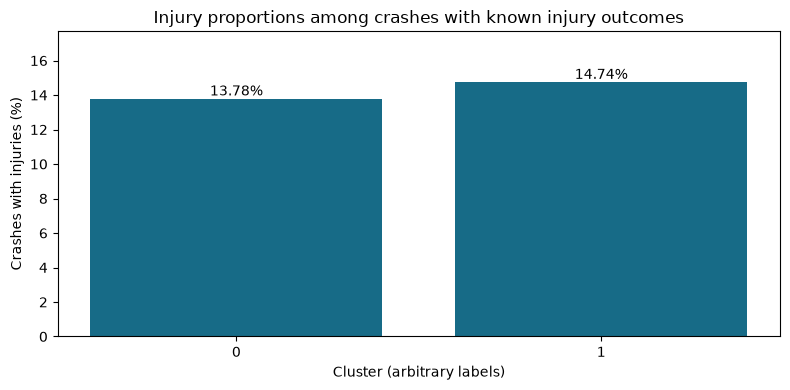

In [8]:
parts=[]
for start in range(0,cohort.height,50_000):
    batch=cohort.slice(start,50_000)
    labels=model.predict(matrix(batch),categorical=CAT_IDX)
    assert len(labels)==batch.height
    parts.append(batch.select('CRASH_RECORD_ID','SOURCE_ROW').with_columns(pl.Series('cluster',labels)))
label_table=pl.concat(parts)
assert label_table.height==cohort.height
assert label_table['CRASH_RECORD_ID'].n_unique()==cohort.height
labeled=cohort.join(label_table.drop('SOURCE_ROW'),on='CRASH_RECORD_ID',how='left',validate='1:1',maintain_order='left')
assert labeled['SOURCE_ROW'].to_list()==cohort['SOURCE_ROW'].to_list()
assert labeled['cluster'].null_count()==0
check=labeled.sample(n=1000,seed=123)
assert np.array_equal(model.predict(matrix(check),categorical=CAT_IDX),check['cluster'].to_numpy())
population=profile(labeled,labeled['cluster'].to_numpy(),'population')
display(population)
category_profiles=[]
for c in CAT:
    counts=labeled.group_by(['cluster',c]).len().sort(['cluster','len'],descending=[False,True])
    top=counts.group_by('cluster',maintain_order=True).head(1).to_pandas()
    for row in top.to_dict('records'):
        n=int(population.loc[population.cluster==row['cluster'],'crashes'].iloc[0])
        category_profiles.append({'cluster':row['cluster'],'feature':c,'mode':row[c],'mode_share_percent':row['len']/n*100})
category_profiles=pd.DataFrame(category_profiles);display(category_profiles)
population.to_csv(REPORTS/'population_profiles.csv',index=False)
category_profiles.to_csv(REPORTS/'categorical_profiles.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));ax.bar(population.cluster.astype(str),population.injury_percent,color='#176b87')
ax.set(xlabel='Cluster (arbitrary labels)',ylabel='Crashes with injuries (%)',title='Injury proportions among crashes with known injury outcomes')
for i,v in enumerate(population.injury_percent):ax.text(i,v,f'{v:.2f}%',ha='center',va='bottom')
ax.set_ylim(0,max(population.injury_percent)*1.2)
fig.tight_layout();fig.savefig(ASSETS/'injury_profiles.png',dpi=160);plt.show()

## Computed findings and execution record
The following statements are generated from this run; they replace previous cluster counts and percentages. Labels are arbitrary and cannot be equated with the original notebook's labels.

In [9]:
print(f'Analyzed {cohort.height:,} eligible crashes during 2016–2025; K={K}, gamma=2.')
for r in population.itertuples():
    print(f'Cluster {r.cluster}: {r.crashes:,} crashes; injury proportion {r.injury_percent:.2f}% among {r.known_injury_outcomes:,} known outcomes.')
print(f'Initialization ARI range: {stability.query("experiment == 'initialization'").ARI.min():.3f} to {stability.query("experiment == 'initialization'").ARI.max():.3f}')
print(f'80% subset ARI range: {stability.query("experiment == '80% training subset'").ARI.min():.3f} to {stability.query("experiment == '80% training subset'").ARI.max():.3f}')
summary={'audit':audit,'K':K,'gamma':2.0,'scale':scale,'versions':versions,
         'python':platform.python_version(),'population':population.to_dict('records'),
         'stability':stability.to_dict('records'),'distance_summary':distance_summary,
         'all_alignment_checks_passed':True}
(REPORTS/'execution_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Execution reached the final code cell; all explicit assertions passed.')

Analyzed 1,006,003 eligible crashes during 2016–2025; K=2, gamma=2.
Cluster 0: 329,743 crashes; injury proportion 13.78% among 328,337 known outcomes.
Cluster 1: 676,260 crashes; injury proportion 14.74% among 675,477 known outcomes.
Initialization ARI range: 0.020 to 0.996
80% subset ARI range: 0.031 to 0.031
Execution reached the final code cell; all explicit assertions passed.


## Interpretation of this execution

The reference partition has K=2 and gamma=2. cluster 0 contains 329,743 crashes with an injury proportion of 13.78% among known injury outcomes; cluster 1 contains 676,260 crashes with an injury proportion of 14.74% among known injury outcomes.

The stability experiments show that the partition is not robust: most initialization runs and all three training subsamples have very low agreement with the reference. Gamma changes also materially alter membership. These results support an exploratory sensitivity finding, not a reliable taxonomy of crash types. Small differences between training and evaluation summaries do not resolve this instability or establish external validity.

## Limitations
- Descriptive associations do not establish causality. Injury proportions among recorded crashes are not traffic exposure rates; there are no vehicle-mile, trip or pedestrian denominators.
- The official source states that citywide coverage begins in September 2017; 2016 and part of 2017 have partial geographic coverage. Crashes outside CPD response jurisdiction, often interstate highways, are excluded. Historical reporting and missing data can vary. The official live export can differ from the audited snapshot.
- K-Prototypes imposes numeric/categorical distances; results depend on features, scaling, clipping, gamma, K, sampling and initialization. A time-of-day category loses within-period detail. No configuration is asserted to represent a uniquely true partition.
- The earlier execution fitted scaling before splitting; its evaluation was not fully independent. This revision corrects that leakage, but reuses a snapshot already examined during project development. Random held-out checks are internal descriptive checks, not temporal or external predictive validation.
- Injury outcomes are excluded from model inputs and selection. Missing injury totals are excluded only from injury-proportion denominators, with counts reported. Posted speed limits do not measure actual vehicle speed.
- No deployed model, measured business impact, causal effect or external predictive validity is claimed. No license has been added.